In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [2]:
project_root = Path("/mnt/x/segmentation_cfos")
useful_image_dir = project_root / "data" / "raw" / "patches_64" / "useful_patches" / "images"
useful_mask_dir = project_root / "data" / "raw" / "patches_64" / "useful_patches" / "masks"
unuseful_image_dir = project_root / "data" / "raw" / "patches_64" / "unuseful_patches" / "images"
unuseful_mask_dir = project_root / "data" / "raw" / "patches_64" / "unuseful_patches" / "masks"

In [3]:
useful_images = sorted(useful_image_dir.glob("*.npy"))
useful_masks = sorted(useful_mask_dir.glob("*.npy"))
unuseful_images = sorted(unuseful_image_dir.glob("*.npy"))
unuseful_masks = sorted(unuseful_mask_dir.glob("*.npy"))

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Useful patches (with neurons or vessels): {len(useful_images)} image-mask pairs")
print(f"Unuseful patches (pure background discarded): {len(unuseful_images)} pairs")
print(f"Total kept for training: {len(useful_images)}")
print(f"Discarded percentage: {len(unuseful_images)/(len(useful_images)+len(unuseful_images))*100:.1f}%")
print("=" * 60)

DATASET OVERVIEW
Useful patches (with neurons or vessels): 1772 image-mask pairs
Unuseful patches (pure background discarded): 472 pairs
Total kept for training: 1772
Discarded percentage: 21.0%


In [4]:
first_image = np.load(useful_images[0])
first_mask = np.load(useful_masks[0])

print(f"\nFirst patch information:")
print(f"  Name: {useful_images[0].name}")
print(f"  Image shape: {first_image.shape}")
print(f"  Image dtype: {first_image.dtype}")
print(f"  Image min: {first_image.min():.2f}, max: {first_image.max():.2f}")
print(f"  Mask shape: {first_mask.shape}")
print(f"  Mask unique values: {np.unique(first_mask)}")
print(f"  Neurons in mask: {np.sum(first_mask == 255)} voxels")


First patch information:
  Name: patch_64_00000001.npy
  Image shape: (64, 64, 64)
  Image dtype: uint16
  Image min: 224.00, max: 706.00
  Mask shape: (64, 64, 64)
  Mask unique values: [  0 255]
  Neurons in mask: 673 voxels


In [5]:
def visualize_patch(image, mask, title="", figsize=(12, 4)):
    """Display image, mask and overlay side by side"""
    middle_z = image.shape[0] // 2
    
    # Normalize image for display
    img_slice = image[middle_z, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    # Mask slice
    msk_slice = mask[middle_z, :, :]
    
    # Create overlay (neurons in red)
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[msk_slice == 255, 0] = 1  # Red channel
    overlay[msk_slice == 255, 1] = 0  # Green channel
    overlay[msk_slice == 255, 2] = 0  # Blue channel
    
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title(f'Image - Slice Z={middle_z}')
    axes[0].axis('off')
    
    axes[1].imshow(msk_slice, cmap='gray')
    axes[1].set_title(f'Mask - Neurons in white')
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title(f'Overlay - Neurons in red')
    axes[2].axis('off')
    
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()



VISUALIZING FIRST 6 USEFUL PATCHES


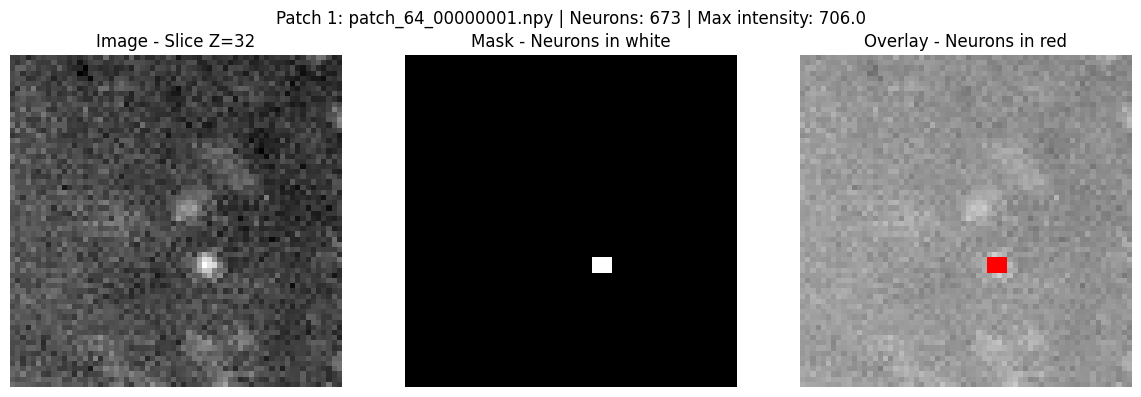

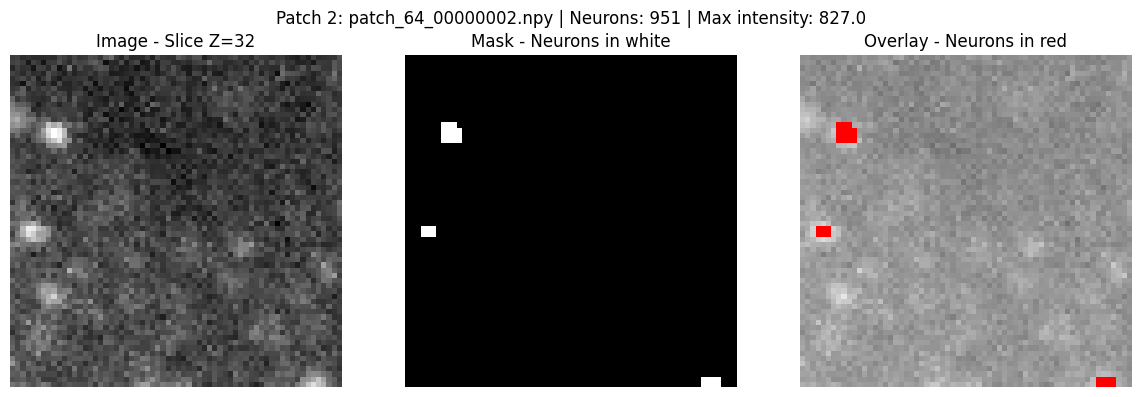

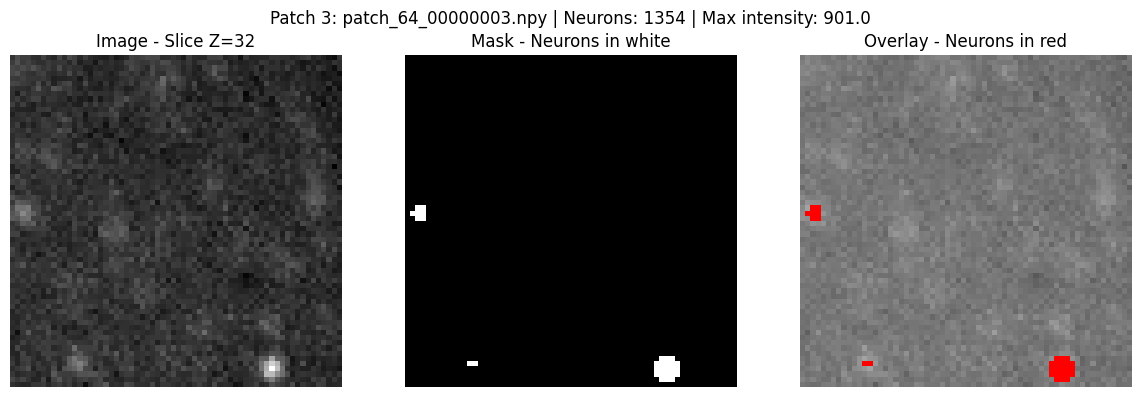

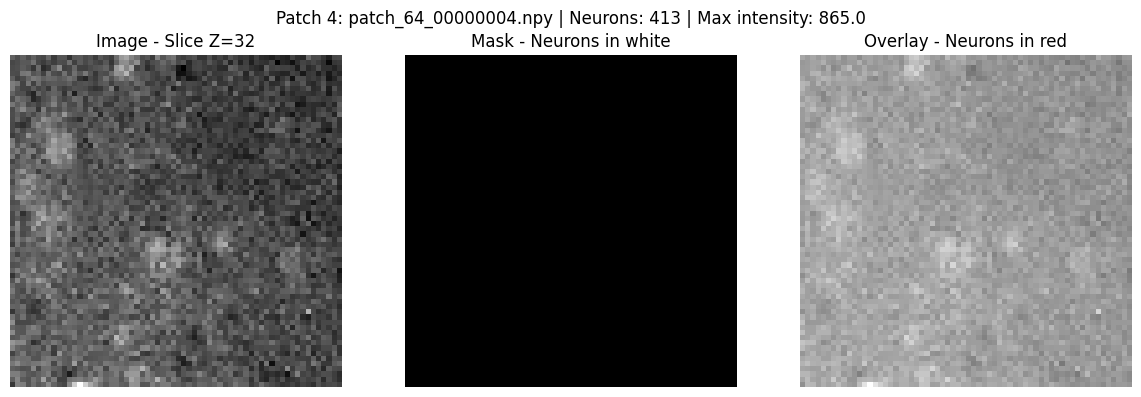

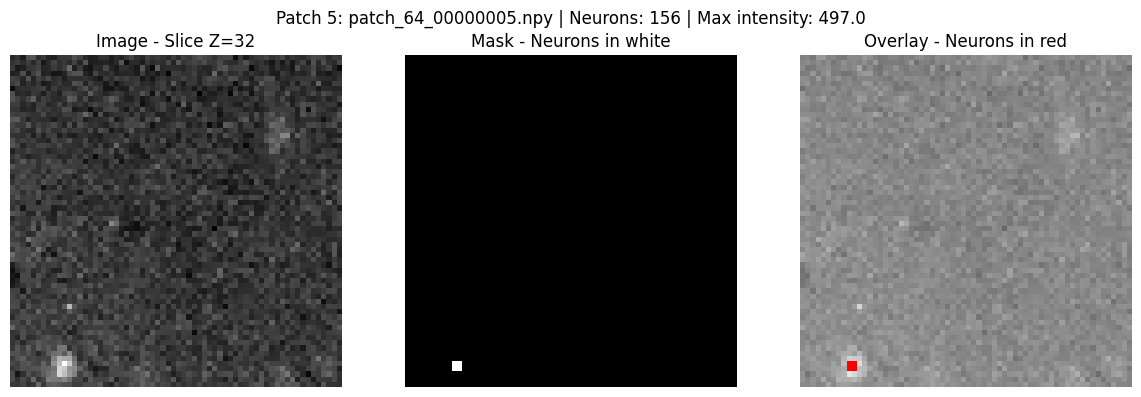

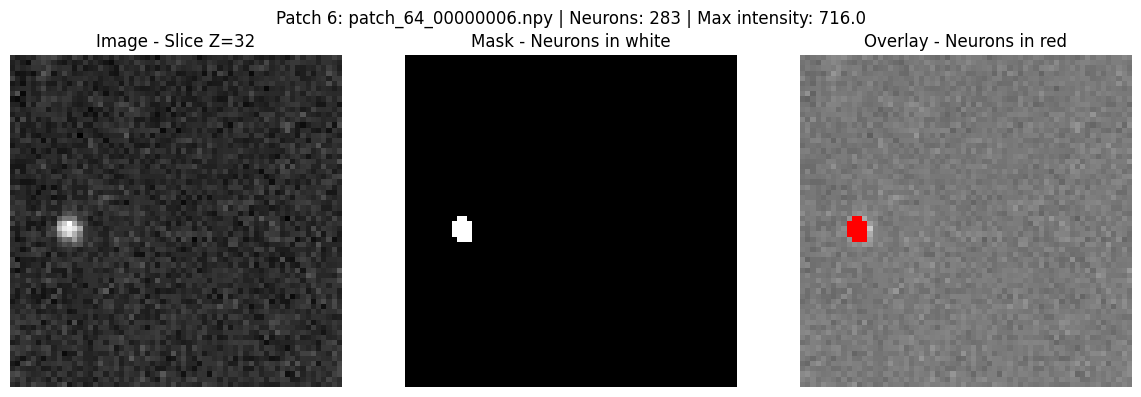

In [6]:
print("\n" + "=" * 60)
print("VISUALIZING FIRST 6 USEFUL PATCHES")
print("=" * 60)

for i in range(min(6, len(useful_images))):
    image = np.load(useful_images[i])
    mask = np.load(useful_masks[i])
    has_neurons = np.sum(mask == 255) > 0
    max_intensity = image.max()
    
    title = f"Patch {i+1}: {useful_images[i].name} | Neurons: {np.sum(mask == 255)} | Max intensity: {max_intensity:.1f}"
    visualize_patch(image, mask, title=title, figsize=(12, 4))

In [7]:
neurons_patches = []
vessels_patches = []

for i, mask_path in enumerate(useful_masks):
    mask = np.load(mask_path)
    if np.sum(mask == 255) > 0:
        neurons_patches.append(i)
    else:
        vessels_patches.append(i)

print("=" * 60)
print("USEFUL PATCHES BREAKDOWN")
print("=" * 60)
print(f"Patches with neurons: {len(neurons_patches)}")
print(f"Patches with vessels/artifacts only (no neurons): {len(vessels_patches)}")
print(f"Total useful: {len(neurons_patches) + len(vessels_patches)}")


USEFUL PATCHES BREAKDOWN
Patches with neurons: 1739
Patches with vessels/artifacts only (no neurons): 33
Total useful: 1772



VESSELS/ARTIFACTS PATCHES (No neurons, high intensity)


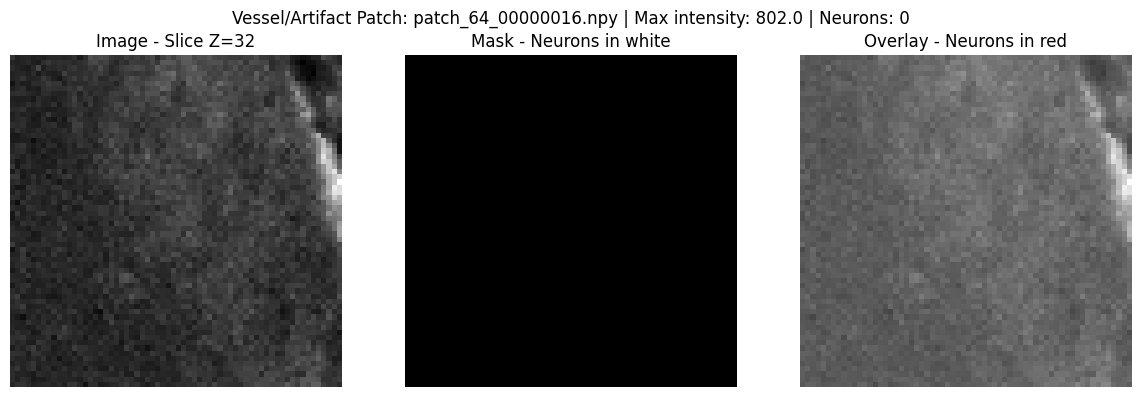

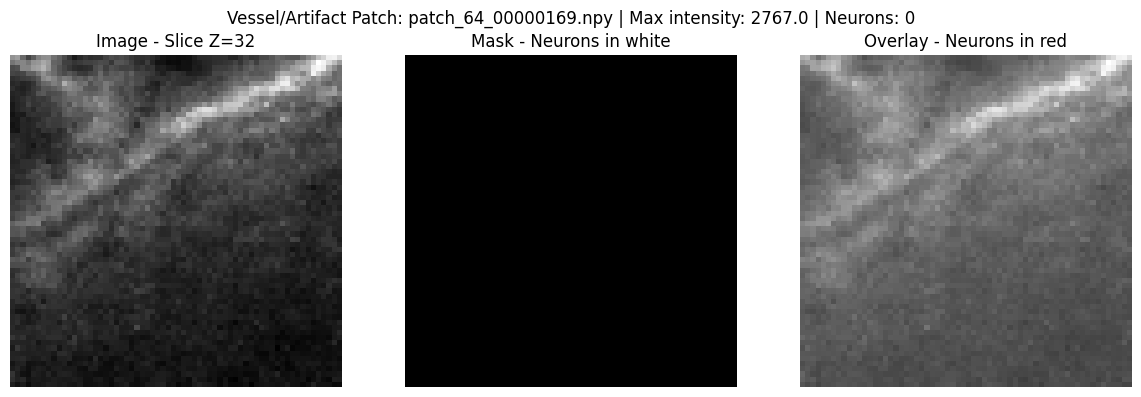

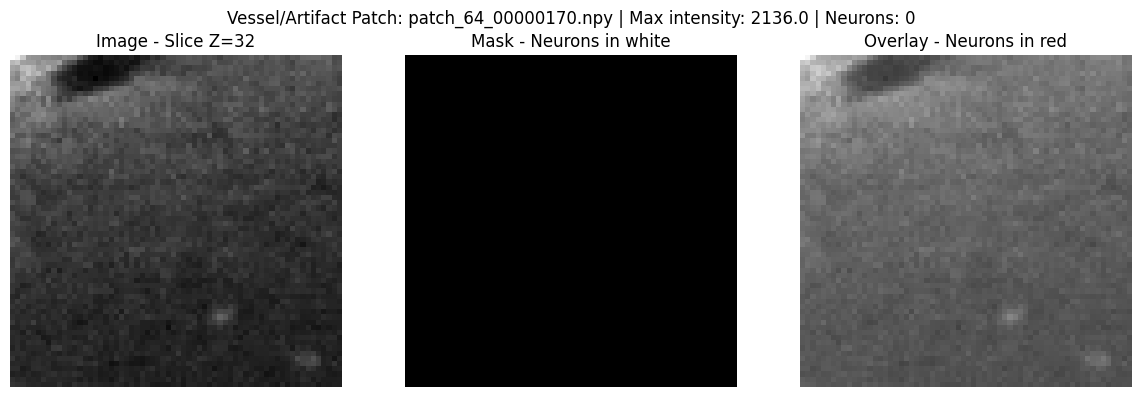

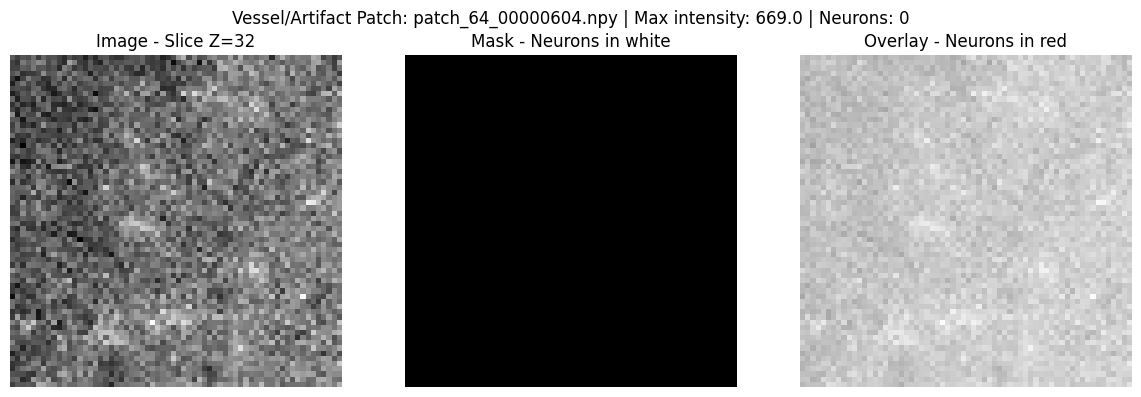

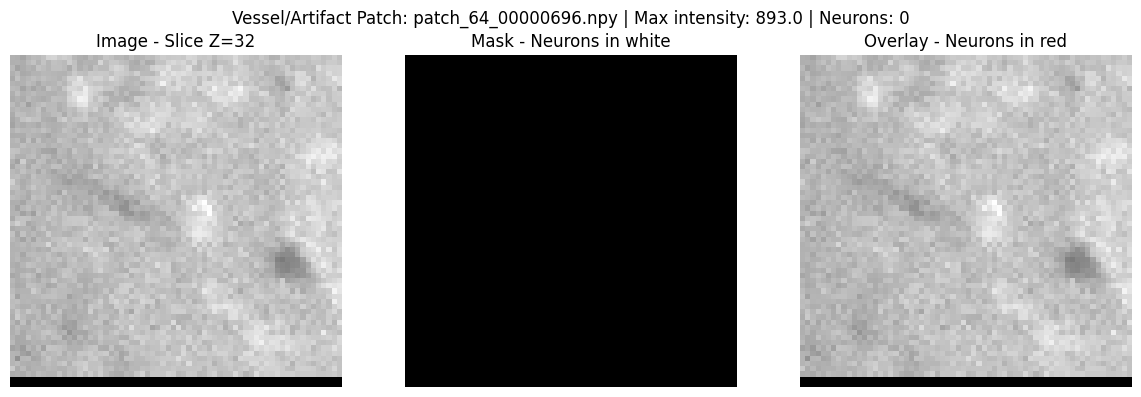

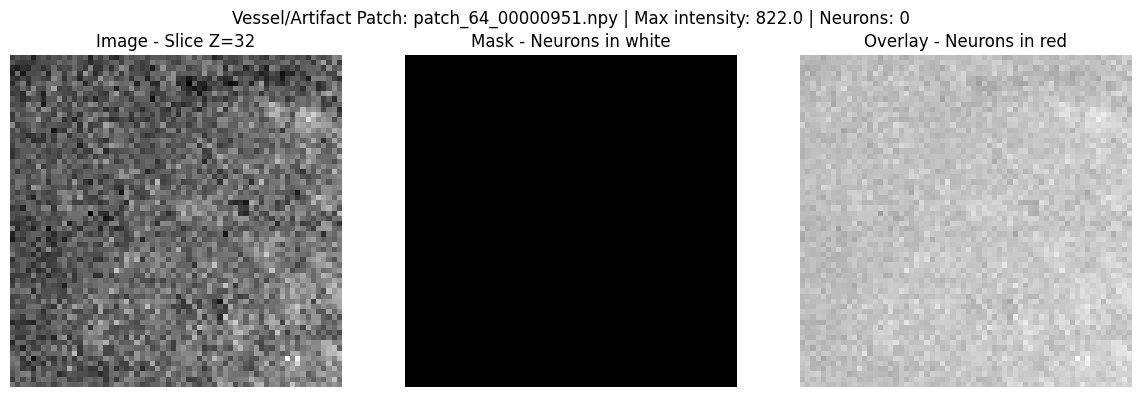

In [8]:
print("\n" + "=" * 60)
print("VESSELS/ARTIFACTS PATCHES (No neurons, high intensity)")
print("=" * 60)

for i in vessels_patches[:6]:
    image = np.load(useful_images[i])
    mask = np.load(useful_masks[i])
    max_intensity = image.max()
    
    title = f"Vessel/Artifact Patch: {useful_images[i].name} | Max intensity: {max_intensity:.1f} | Neurons: 0"
    visualize_patch(image, mask, title=title, figsize=(12, 4))

In [9]:
def compute_patch_statistics(image_files, mask_files, max_patches=None):
    """Compute statistics for a list of patches"""
    if max_patches:
        image_files = image_files[:max_patches]
        mask_files = mask_files[:max_patches]
    
    stats = {
        "num_patches": len(image_files),
        "neuron_voxels_per_patch": [],
        "max_intensity_per_patch": [],
        "has_neurons": 0
    }
    
    for img_path, msk_path in zip(image_files, mask_files):
        image = np.load(img_path)
        mask = np.load(msk_path)
        
        neuron_voxels = np.sum(mask == 255)
        stats["neuron_voxels_per_patch"].append(neuron_voxels)
        stats["max_intensity_per_patch"].append(image.max())
        
        if neuron_voxels > 0:
            stats["has_neurons"] += 1
    
    return stats


In [10]:
print("\n" + "=" * 60)
print("COMPREHENSIVE STATISTICS")
print("=" * 60)

stats = compute_patch_statistics(useful_images, useful_masks)

neuron_voxels = np.array(stats["neuron_voxels_per_patch"])
max_intensities = np.array(stats["max_intensity_per_patch"])
neuron_voxels_nonzero = neuron_voxels[neuron_voxels > 0]

print(f"Total useful patches: {stats['num_patches']}")
print(f"Patches with at least one neuron: {stats['has_neurons']}")
print(f"Patches with vessels/artifacts only: {stats['num_patches'] - stats['has_neurons']}")
print()
print("Neuron voxels per patch (all useful patches):")
print(f"  Min: {neuron_voxels.min()}")
print(f"  Max: {neuron_voxels.max()}")
print(f"  Mean: {neuron_voxels.mean():.2f}")
print(f"  Median: {np.median(neuron_voxels):.2f}")
print()
if len(neuron_voxels_nonzero) > 0:
    print("Neuron voxels per patch (only patches with neurons):")
    print(f"  Min: {neuron_voxels_nonzero.min()}")
    print(f"  Max: {neuron_voxels_nonzero.max()}")
    print(f"  Mean: {neuron_voxels_nonzero.mean():.2f}")
    print(f"  Median: {np.median(neuron_voxels_nonzero):.2f}")
print()
print("Max intensity per patch:")
print(f"  Min: {max_intensities.min():.2f}")
print(f"  Max: {max_intensities.max():.2f}")
print(f"  Mean: {max_intensities.mean():.2f}")
print(f"  Median: {np.median(max_intensities):.2f}")



COMPREHENSIVE STATISTICS
Total useful patches: 1772
Patches with at least one neuron: 1739
Patches with vessels/artifacts only: 33

Neuron voxels per patch (all useful patches):
  Min: 0
  Max: 6849
  Mean: 414.97
  Median: 181.00

Neuron voxels per patch (only patches with neurons):
  Min: 1
  Max: 6849
  Mean: 422.84
  Median: 190.00

Max intensity per patch:
  Min: 265.00
  Max: 4231.00
  Mean: 1011.29
  Median: 867.00


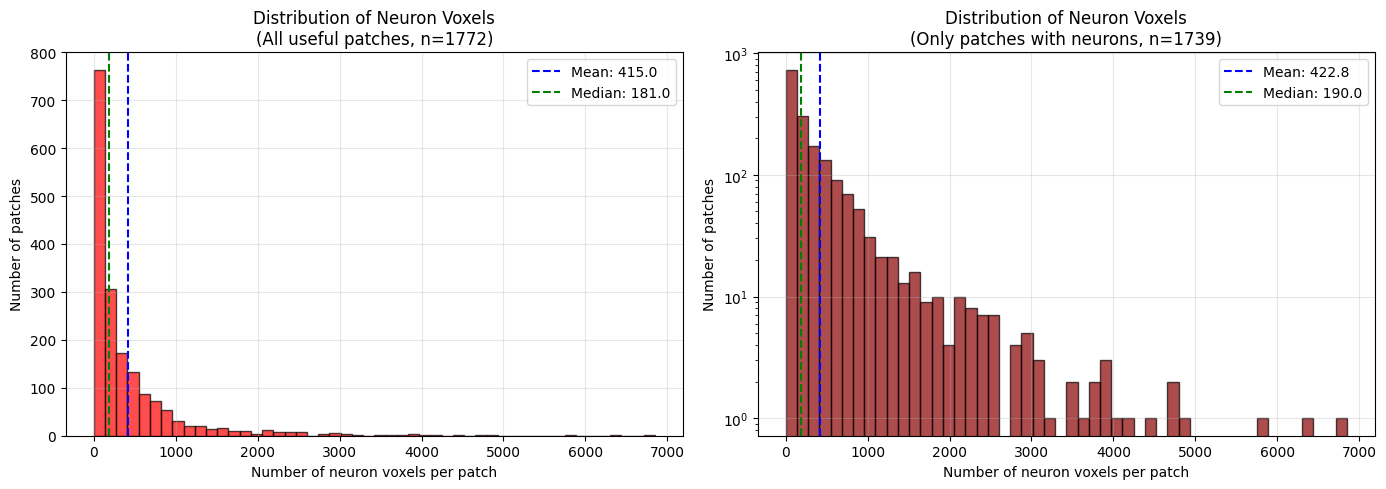

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# All patches
axes[0].hist(neuron_voxels, bins=50, edgecolor='black', alpha=0.7, color='red')
axes[0].set_xlabel('Number of neuron voxels per patch')
axes[0].set_ylabel('Number of patches')
axes[0].set_title(f'Distribution of Neuron Voxels\n(All useful patches, n={len(neuron_voxels)})')
axes[0].axvline(x=np.mean(neuron_voxels), color='blue', linestyle='--', label=f'Mean: {neuron_voxels.mean():.1f}')
axes[0].axvline(x=np.median(neuron_voxels), color='green', linestyle='--', label=f'Median: {np.median(neuron_voxels):.1f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Only patches with neurons (log scale)
if len(neuron_voxels_nonzero) > 0:
    axes[1].hist(neuron_voxels_nonzero, bins=50, edgecolor='black', alpha=0.7, color='darkred')
    axes[1].set_xlabel('Number of neuron voxels per patch')
    axes[1].set_ylabel('Number of patches')
    axes[1].set_title(f'Distribution of Neuron Voxels\n(Only patches with neurons, n={len(neuron_voxels_nonzero)})')
    axes[1].axvline(x=np.mean(neuron_voxels_nonzero), color='blue', linestyle='--', label=f'Mean: {neuron_voxels_nonzero.mean():.1f}')
    axes[1].axvline(x=np.median(neuron_voxels_nonzero), color='green', linestyle='--', label=f'Median: {np.median(neuron_voxels_nonzero):.1f}')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].set_yscale('log')

plt.tight_layout()
plt.show()


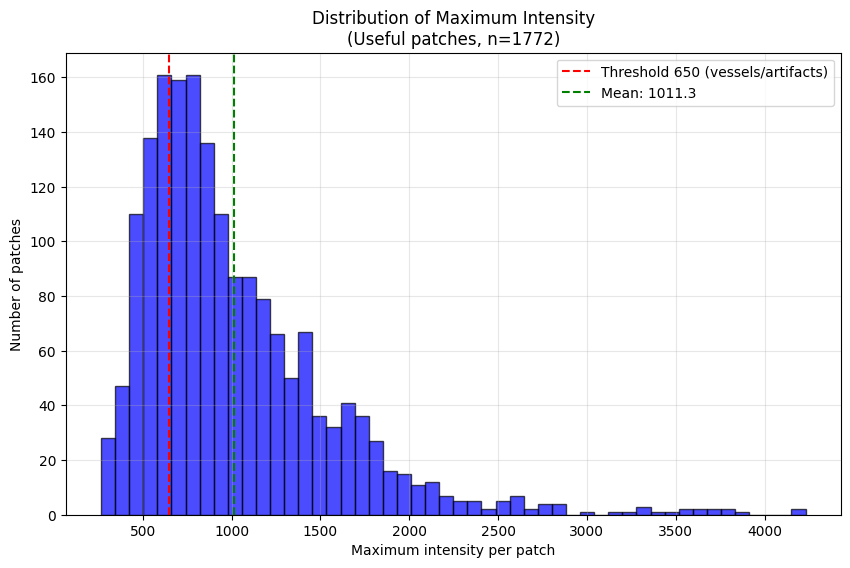

In [14]:
plt.figure(figsize=(10, 6))
plt.hist(max_intensities, bins=50, edgecolor='black', alpha=0.7, color='blue')
plt.xlabel('Maximum intensity per patch')
plt.ylabel('Number of patches')
plt.title(f'Distribution of Maximum Intensity\n(Useful patches, n={len(max_intensities)})')
plt.axvline(x=650, color='red', linestyle='--', label='Threshold 650 (vessels/artifacts)')
plt.axvline(x=np.mean(max_intensities), color='green', linestyle='--', label=f'Mean: {max_intensities.mean():.1f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



Patch with most neurons: patch_64_00000348.npy
  Neuron voxels: 6849
  Max intensity: 1784.0


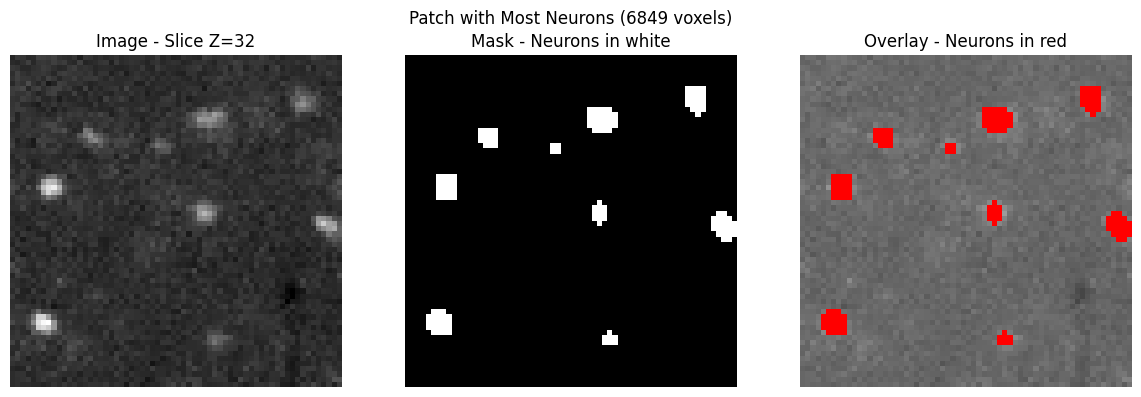

In [15]:
idx_max_neurons = np.argmax(neuron_voxels)
print(f"\nPatch with most neurons: {useful_images[idx_max_neurons].name}")
print(f"  Neuron voxels: {neuron_voxels[idx_max_neurons]}")
print(f"  Max intensity: {max_intensities[idx_max_neurons]:.1f}")

image_max = np.load(useful_images[idx_max_neurons])
mask_max = np.load(useful_masks[idx_max_neurons])
visualize_patch(image_max, mask_max, title=f"Patch with Most Neurons ({neuron_voxels[idx_max_neurons]} voxels)")



Patch with highest intensity: patch_64_00000920.npy
  Max intensity: 4231.0
  Neuron voxels: 113


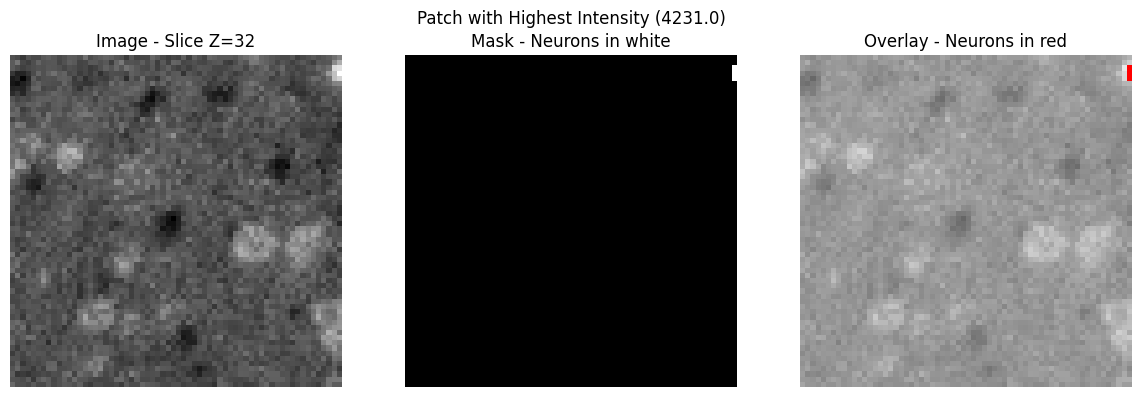

In [16]:
idx_max_intensity = np.argmax(max_intensities)
print(f"\nPatch with highest intensity: {useful_images[idx_max_intensity].name}")
print(f"  Max intensity: {max_intensities[idx_max_intensity]:.1f}")
print(f"  Neuron voxels: {neuron_voxels[idx_max_intensity]}")

image_high = np.load(useful_images[idx_max_intensity])
mask_high = np.load(useful_masks[idx_max_intensity])
visualize_patch(image_high, mask_high, title=f"Patch with Highest Intensity ({max_intensities[idx_max_intensity]:.1f})")

In [17]:
def show_patches_grid(patch_indices, num_cols=4):
    """Display multiple patches in a grid"""
    num_patches = len(patch_indices)
    num_rows = (num_patches + num_cols - 1) // num_cols
    
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(4*num_cols, 4*num_rows))
    if num_rows == 1:
        axes = axes.reshape(1, -1)
    
    for idx, patch_idx in enumerate(patch_indices):
        row = idx // num_cols
        col = idx % num_cols
        
        image = np.load(useful_images[patch_idx])
        mask = np.load(useful_masks[patch_idx])
        middle_z = image.shape[0] // 2
        
        img_slice = image[middle_z, :, :]
        if img_slice.max() > 1:
            img_slice = img_slice / img_slice.max()
        
        msk_slice = mask[middle_z, :, :]
        
        # Overlay
        overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
        overlay[msk_slice == 255, 0] = 1
        overlay[msk_slice == 255, 1] = 0
        overlay[msk_slice == 255, 2] = 0
        
        axes[row, col].imshow(overlay)
        axes[row, col].set_title(f'Patch {patch_idx+1}\nNeurons: {np.sum(mask==255)}')
        axes[row, col].axis('off')
    
    # Hide empty subplots
    for idx in range(len(patch_indices), num_rows * num_cols):
        row = idx // num_cols
        col = idx % num_cols
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()



Showing 12 random useful patches


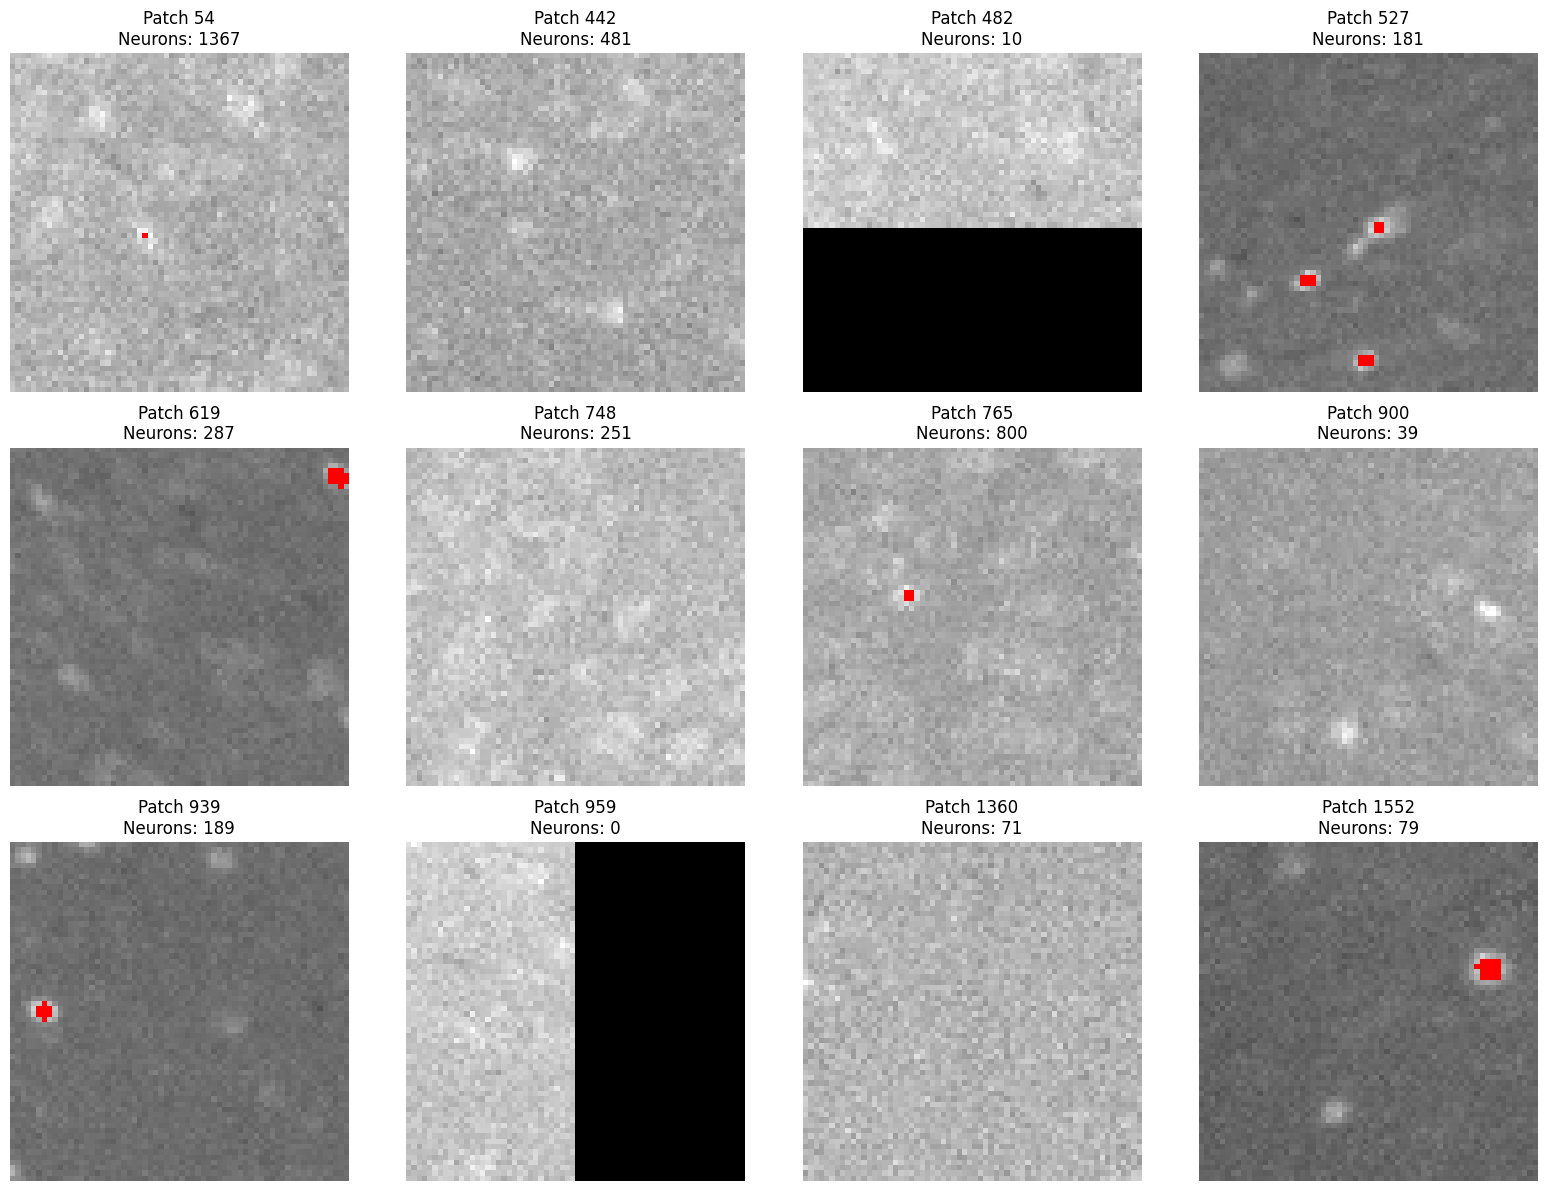

In [18]:
num_to_show = 12
random_indices = np.random.choice(len(useful_images), min(num_to_show, len(useful_images)), replace=False)
random_indices = sorted(random_indices)

print(f"\nShowing {len(random_indices)} random useful patches")
show_patches_grid(random_indices, num_cols=4)



Showing top 12 patches with most neurons


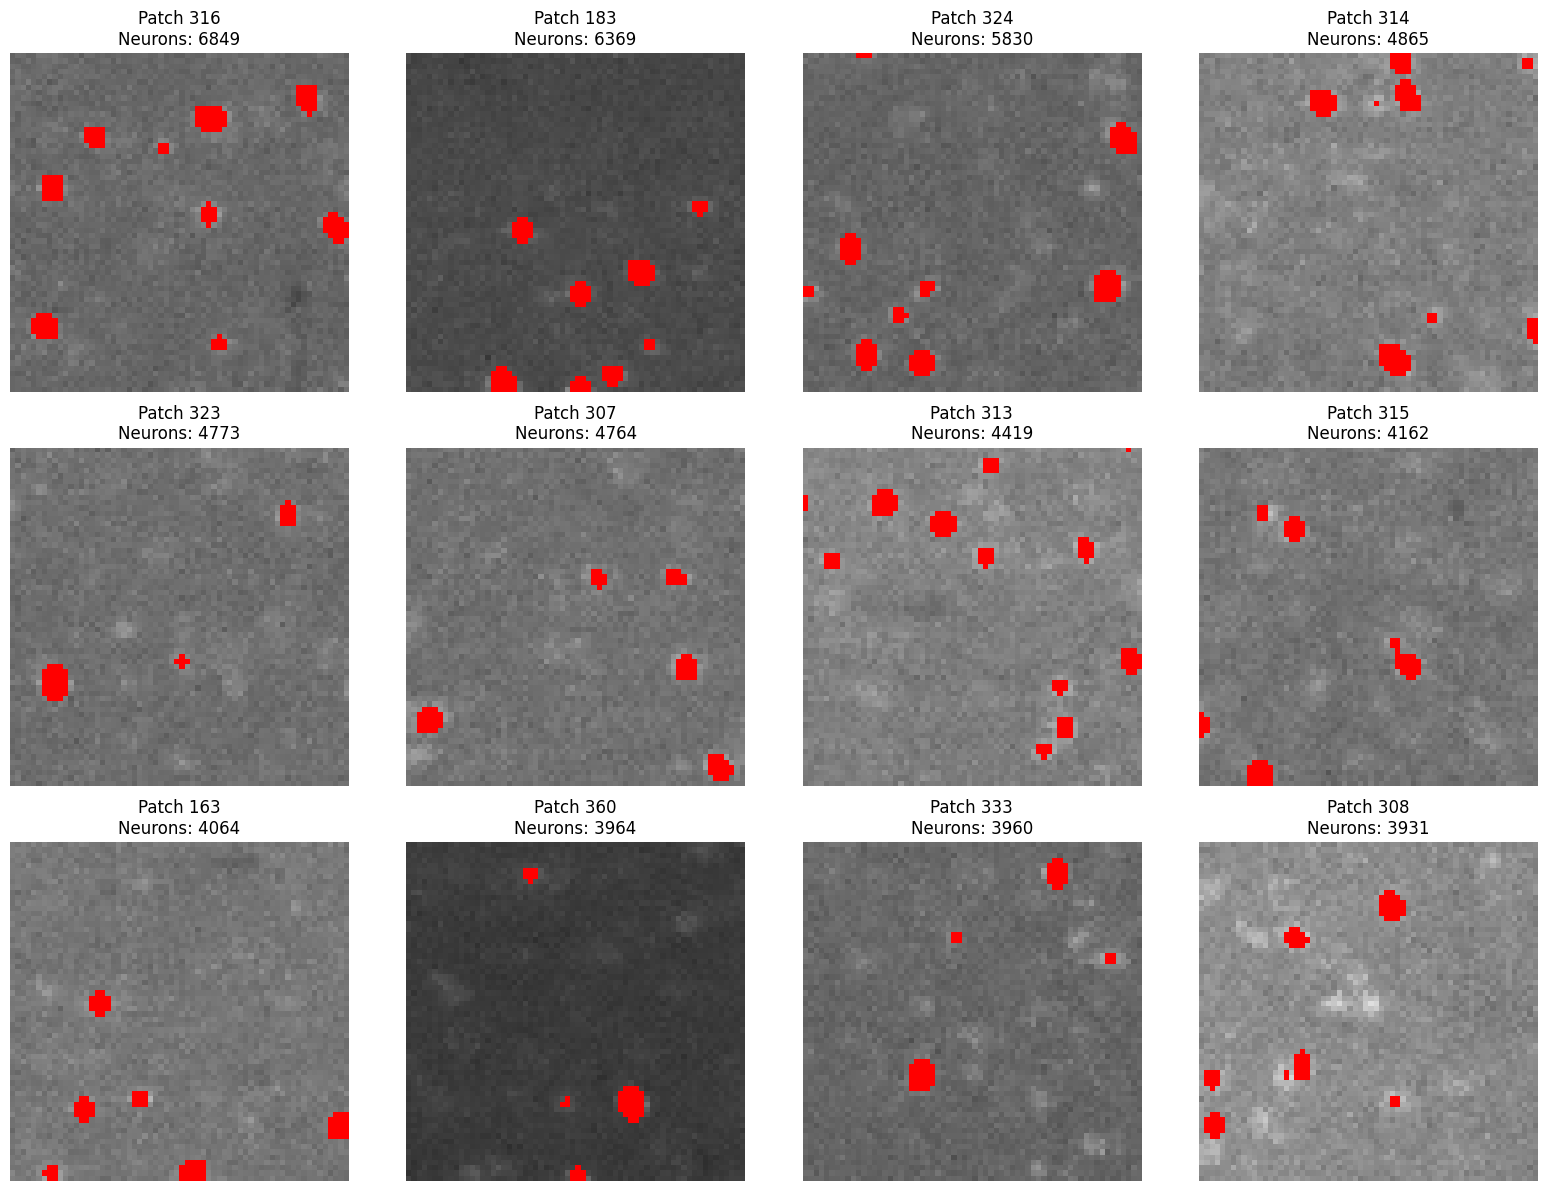

In [19]:
top_neurons_indices = np.argsort(neuron_voxels)[-12:][::-1]  # Top 12 patches with most neurons
print(f"\nShowing top {len(top_neurons_indices)} patches with most neurons")
show_patches_grid(top_neurons_indices, num_cols=4)

In [20]:
print("\n" + "=" * 70)
print("FINAL SUMMARY REPORT")
print("=" * 70)
print(f"Dataset: Useful Patches")
print(f"Total patches for training: {len(useful_images)}")
print(f"  - Patches with neurons: {stats['has_neurons']}")
print(f"  - Patches with vessels/artifacts only: {len(useful_images) - stats['has_neurons']}")
print()
print("Neuron statistics:")
print(f"  - Total neuron voxels across all patches: {neuron_voxels.sum()}")
if len(neuron_voxels_nonzero) > 0:
    avg_neuron_size = neuron_voxels_nonzero.mean()
    estimated_neurons = neuron_voxels.sum() / avg_neuron_size if avg_neuron_size > 0 else 0
    print(f"  - Estimated number of neurons (assuming avg {avg_neuron_size:.0f} voxels/neuron): {estimated_neurons:.0f}")
print()
print("Intensity statistics:")
print(f"  - Patches with high intensity (>650): {sum(1 for i in max_intensities if i > 650)}")
print(f"  - Patches with very high intensity (>1000): {sum(1 for i in max_intensities if i > 1000)}")
print("=" * 70)



FINAL SUMMARY REPORT
Dataset: Useful Patches
Total patches for training: 1772
  - Patches with neurons: 1739
  - Patches with vessels/artifacts only: 33

Neuron statistics:
  - Total neuron voxels across all patches: 735326
  - Estimated number of neurons (assuming avg 423 voxels/neuron): 1739

Intensity statistics:
  - Patches with high intensity (>650): 1315
  - Patches with very high intensity (>1000): 695


In [21]:
import json
output_dir = project_root / "outputs" / "statistics"
output_dir.mkdir(parents=True, exist_ok=True)

report = {
    "total_useful_patches": len(useful_images),
    "patches_with_neurons": stats["has_neurons"],
    "patches_with_vessels_only": len(useful_images) - stats["has_neurons"],
    "total_neuron_voxels": int(neuron_voxels.sum()),
    "neuron_voxels_per_patch": {
        "min": float(neuron_voxels.min()),
        "max": float(neuron_voxels.max()),
        "mean": float(neuron_voxels.mean()),
        "median": float(np.median(neuron_voxels))
    },
    "max_intensity_per_patch": {
        "min": float(max_intensities.min()),
        "max": float(max_intensities.max()),
        "mean": float(max_intensities.mean()),
        "median": float(np.median(max_intensities))
    }
}

with open(output_dir / "useful_patches_statistics.json", "w") as f:
    json.dump(report, f, indent=2)

print(f"\nStatistics saved to: {output_dir / 'useful_patches_statistics.json'}")


Statistics saved to: /mnt/x/segmentation_cfos/outputs/statistics/useful_patches_statistics.json
